In [2]:
!nvidia-smi

Thu Nov 26 14:21:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [4]:
from datasets import load_dataset

df = load_dataset("bentrevett/multi30k")
print(df.shape)

README.md:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/4.60M [00:00<?, ?B/s]

val.jsonl:   0%|          | 0.00/164k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/156k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

{'train': (29000, 2), 'validation': (1014, 2), 'test': (1000, 2)}


In [5]:
train = df["train"]
print(len(train))

29000


In [6]:
validate = df["validation"]
print(len(validate))

1014


In [7]:
test = df["test"]
print(len(test))

1000


In [8]:
print("German:", train[0]["de"])
print("English:", train[0]["en"])

German: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.
English: Two young, White males are outside near many bushes.


In [9]:
train_df = pd.DataFrame({
    "German": train["de"],
    "English": train["en"]
})

val_df = pd.DataFrame({
    "German": validate["de"],
    "English": validate["en"]
})

test_df = pd.DataFrame({
    "German": test["de"],
    "English": test["en"]
})

print(train_df.sample(5, random_state=42))

                                                  German  \
2884   Ein kleiner Junge mit Sweatshirt und Stiefeln,...   
12220  Mehrere Personen in blauer und grüner Kleidung...   
20437  Ein Mann in weißer kurzer Hose wirft in einem ...   
25172  Ein rot gekleidete Mann steht hinter den Kette...   
20676  Eine ältere Frau geht durch den Regen und hält...   

                                                 English  
2884   Little boy pulling a green wagon wearing a swe...  
12220  Several people stand outside, singing in blue ...  
20437  A man in white shorts is in a park throwing a ...  
25172  The man in red stands behind the chains while ...  
20676  An older woman walks in the rain holding a red...  


In [10]:
train_df.nunique()

,0
German,28975
English,28991


In [11]:
train_df.isnull().sum()

,0
German,0
English,0


In [12]:
train_df.duplicated().sum()

np.int64(3)

In [13]:
train_df = train_df.drop_duplicates(subset=["German", "English"]).reset_index(drop=True)
print(train_df.duplicated())

0        False
1        False
2        False
3        False
4        False
         ...  
28992    False
28993    False
28994    False
28995    False
28996    False
Length: 28997, dtype: bool


In [14]:
print(train_df["German"].head())
print(train_df["English"].head())

0    Zwei junge weiße Männer sind im Freien in der ...
1    Mehrere Männer mit Schutzhelmen bedienen ein A...
2    Ein kleines Mädchen klettert in ein Spielhaus ...
3    Ein Mann in einem blauen Hemd steht auf einer ...
4    Zwei Männer stehen am Herd und bereiten Essen zu.
Name: German, dtype: object
0    Two young, White males are outside near many b...
1    Several men in hard hats are operating a giant...
2      A little girl climbing into a wooden playhouse.
3    A man in a blue shirt is standing on a ladder ...
4             Two men are at the stove preparing food.
Name: English, dtype: object


In [15]:
train_df.columns

Index(['German', 'English'], dtype='object')

In [16]:
train_df["German_Length"] = train_df["German"].apply(
    lambda x: len(x.split())
)

train_df["English_Length"] = train_df["English"].apply(
    lambda x: len(x.split())
)

In [17]:
train_df.describe()

,German_Length,English_Length
count,28997.000000,28997.000000
mean,11.117150,11.897748
std,3.837591,3.800034
min,1.000000,3.000000
25%,8.000000,9.000000
50%,11.000000,11.000000
75%,13.000000,14.000000
max,39.000000,37.000000


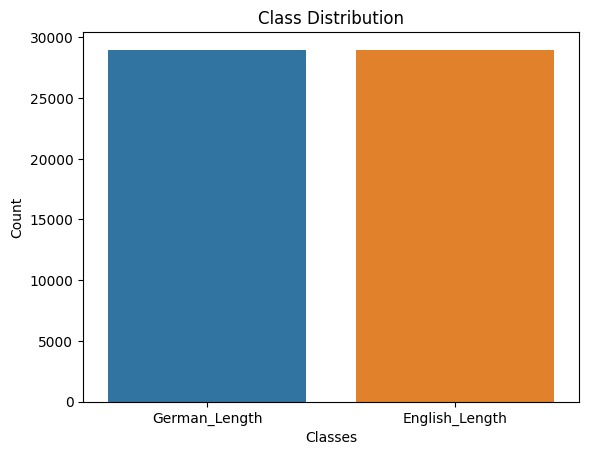

In [18]:
sns.countplot(data=train_df)
plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Count")
plt.show()

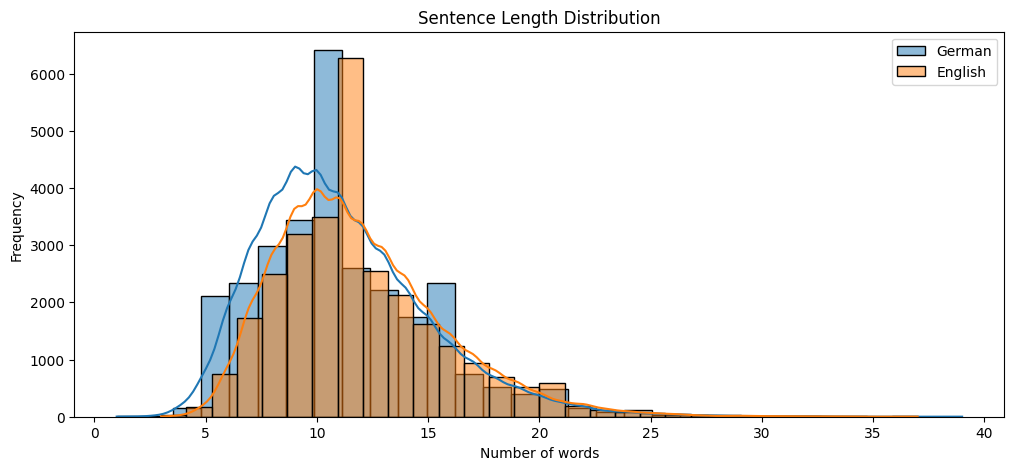

In [19]:
plt.figure(figsize=(12, 5))

sns.histplot(
    train_df["German_Length"],
    bins=30,
    kde=True,
    label="German",
    alpha=0.5
)

sns.histplot(
    train_df["English_Length"],
    bins=30,
    kde=True,
    label="English",
    alpha=0.5
)

plt.title("Sentence Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [20]:
from collections import Counter

german_words = Counter(
    word.lower()
    for sentence in train_df["German"]
    for word in sentence.split()
)

english_words = Counter(
    word.lower()
    for sentence in train_df["English"]
    for word in sentence.split()
)

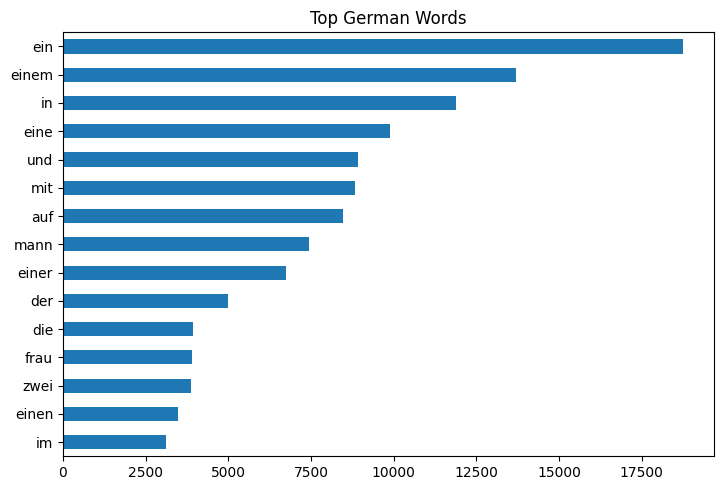

In [21]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

pd.Series(
    dict(german_words.most_common(15))
).sort_values().plot(kind="barh")

plt.title("Top German Words")
plt.tight_layout()
plt.show()

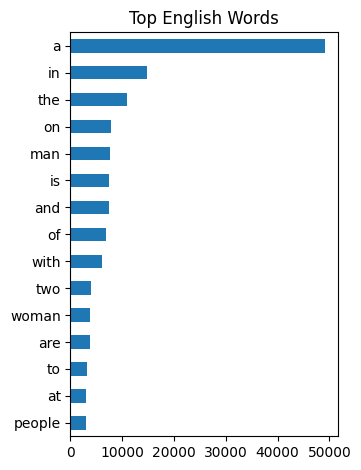

In [22]:
plt.subplot(1, 2, 2)

pd.Series(
    dict(english_words.most_common(15))
).sort_values().plot(kind="barh")

plt.title("Top English Words")
plt.tight_layout()
plt.show()

In [23]:
import re

def clean_text(text):

    text = text.lower().strip()

    text = re.sub(r"\s+", " ", text)

    text = re.sub(
        r"([?.!,;:])",
        r" \1 ",
        text
    )

    text = re.sub(r"\s+", " ", text)

    return text.strip()


train_df["German"] = train_df["German"].apply(clean_text)
train_df["English"] = train_df["English"].apply(clean_text)

val_df["German"] = val_df["German"].apply(clean_text)
val_df["English"] = val_df["English"].apply(clean_text)

test_df["German"] = test_df["German"].apply(clean_text)
test_df["English"] = test_df["English"].apply(clean_text)

In [24]:
train_df["English"] = (
    "startseq " + train_df["English"] + " endseq"
)

val_df["English"] = (
    "startseq " + val_df["English"] + " endseq"
)

test_df["English"] = (
    "startseq " + test_df["English"] + " endseq"
)

print("German:", train_df.iloc[0]["German"])
print("English:", train_df.iloc[0]["English"])

German: zwei junge weiße männer sind im freien in der nähe vieler büsche .
English: startseq two young , white males are outside near many bushes . endseq


In [25]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

german_vectorizer = TextVectorization(
    max_tokens=12000,
    output_mode="int",
    output_sequence_length=40,
    standardize=None
)

english_vectorizer = TextVectorization(
    max_tokens=12000,
    output_mode="int",
    output_sequence_length=40,
    standardize=None
)

In [26]:
german_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["German"].values
    ).batch(256)
)

english_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["English"].values
    ).batch(256)
)

GERMAN_VOCAB_SIZE = german_vectorizer.vocabulary_size()
ENGLISH_VOCAB_SIZE = english_vectorizer.vocabulary_size()

print("German vocabulary:", GERMAN_VOCAB_SIZE)
print("English vocabulary:", ENGLISH_VOCAB_SIZE)

German vocabulary: 12000
English vocabulary: 10527


In [27]:
print("German vocabulary:")
print(german_vectorizer.get_vocabulary()[:30])

print("\nEnglish vocabulary:")
print(english_vectorizer.get_vocabulary()[:30])

German vocabulary:
['', '[UNK]', np.str_('.'), np.str_('ein'), np.str_('einem'), np.str_('in'), np.str_('eine'), np.str_(','), np.str_('und'), np.str_('mit'), np.str_('auf'), np.str_('mann'), np.str_('einer'), np.str_('der'), np.str_('frau'), np.str_('die'), np.str_('zwei'), np.str_('einen'), np.str_('im'), np.str_('an'), np.str_('von'), np.str_('sich'), np.str_('dem'), np.str_('mädchen'), np.str_('junge'), np.str_('vor'), np.str_('zu'), np.str_('steht'), np.str_('männer'), np.str_('sitzt')]

English vocabulary:
['', '[UNK]', np.str_('a'), np.str_('startseq'), np.str_('endseq'), np.str_('.'), np.str_('in'), np.str_('the'), np.str_('on'), np.str_('man'), np.str_('is'), np.str_('and'), np.str_('of'), np.str_('with'), np.str_(','), np.str_('woman'), np.str_('two'), np.str_('are'), np.str_('to'), np.str_('people'), np.str_('at'), np.str_('an'), np.str_('wearing'), np.str_('young'), np.str_('white'), np.str_('shirt'), np.str_('black'), np.str_('his'), np.str_('while'), np.str_('blue')]


In [28]:
german_sequences = german_vectorizer(train_df["German"].values)
english_sequences = english_vectorizer(train_df["English"].values)

print("German sequence:")
print(german_sequences[0].numpy())

print("\nEnglish sequence:")
print(english_sequences[0].numpy())

German sequence:
[  16   24  249   28   82   18   86    5   13  108 5555 3469    2    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]

English sequence:
[   3   16   23   14   24  775   17   56   79  194 1334    5    4    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


In [29]:
english_vocab = english_vectorizer.get_vocabulary()

START_ID = english_vocab.index("startseq")
END_ID = english_vocab.index("endseq")

print("Padding ID:", 0)
print("Unknown ID:", 1)
print("Start ID:", START_ID)
print("End ID:", END_ID)

Padding ID: 0
Unknown ID: 1
Start ID: 3
End ID: 4


In [30]:
X_train_de = german_vectorizer(train_df["German"].values)
Y_train = english_vectorizer(train_df["English"].values)

X_val_de = german_vectorizer(val_df["German"].values)
Y_val = english_vectorizer(val_df["English"].values)

X_test_de = german_vectorizer(test_df["German"].values)
Y_test = english_vectorizer(test_df["English"].values)

In [31]:
decoder_train = Y_train[:, :-1]
target_train = Y_train[:, 1:]

decoder_val = Y_val[:, :-1]
target_val = Y_val[:, 1:]

decoder_test = Y_test[:, :-1]
target_test = Y_test[:, 1:]

print("Encoder input:", X_train_de.shape)
print("Decoder input:", decoder_train.shape)
print("Expected output:", target_train.shape)

Encoder input: (28997, 40)
Decoder input: (28997, 39)
Expected output: (28997, 39)


In [32]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_train_de, decoder_train),
        target_train
    )
)

train_dataset = (
    train_dataset
    .shuffle(10000, seed=42)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_val_de, decoder_val),
        target_val
    )
)

val_dataset = (
    val_dataset
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_test_de, decoder_test),
        target_test
    )
)

test_dataset = (
    test_dataset
    .batch(42)
    .prefetch(tf.data.AUTOTUNE)
)

In [33]:
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

In [34]:

def masked_loss(y_true, y_pred):

    loss = loss_function(y_true, y_pred)

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        loss.dtype
    )

    masked_loss_values = loss * mask

    sentence_loss = (
        tf.reduce_sum(masked_loss_values, axis=-1)
        / tf.maximum(
            tf.reduce_sum(mask, axis=-1),
            1.0
        )
    )

    return sentence_loss


In [35]:
def masked_accuracy(y_true, y_pred):

    predictions = tf.argmax(
        y_pred,
        axis=-1,
        output_type=y_true.dtype
    )

    correct = tf.cast(
        tf.equal(y_true, predictions),
        tf.float32
    )

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        tf.float32
    )

    sentence_accuracy = (
        tf.reduce_sum(correct * mask, axis=-1)
        / tf.maximum(
            tf.reduce_sum(mask, axis=-1),
            1.0
        )
    )

    return sentence_accuracy


In [36]:
class RemoveMask(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.identity(inputs)

    def compute_mask(self, inputs, mask=None):
        return None


In [37]:
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout, AdditiveAttention, Concatenate, LayerNormalization

def build_seq2seq_model(rnn_type, use_attention=False, model_name="Seq2Seq"):

    source_input = Input(
        shape=(40,),
        name="german_input"
    )

    target_input = Input(
        shape=(39,),
        name="english_input"
    )


    source_mask = source_input != 0
    target_mask = target_input != 0


    source_embedding = Embedding(
        GERMAN_VOCAB_SIZE,
        128,
        mask_zero=True,
        name=f"{model_name}_source_embedding"
    )(source_input)

    target_embedding = Embedding(
        ENGLISH_VOCAB_SIZE,
        128,
        mask_zero=True,
        name=f"{model_name}_target_embedding"
    )(target_input)


    encoder_outputs = source_embedding
    encoder_states = []

    for i in range(2):

        encoder = rnn_type(
            256,
            return_sequences=True,
            return_state=True,
            dropout=0.2,
            name=f"{model_name}_encoder_{i+1}"
        )

        result = encoder(encoder_outputs)

        encoder_outputs = result[0]
        encoder_states.append(result[1:])


    decoder_outputs = target_embedding

    for i in range(2):

        decoder = rnn_type(
            256,
            return_sequences=True,
            return_state=True,
            dropout=0.2,
            name=f"{model_name}_decoder_{i+1}"
        )

        result = decoder(
            decoder_outputs,
            initial_state=encoder_states[i]
        )

        decoder_outputs = result[0]


    if use_attention:

        attention = AdditiveAttention(
            name=f"{model_name}_attention"
        )

        context = attention(
            [decoder_outputs, encoder_outputs],
            mask=[target_mask, source_mask]
        )

        decoder_outputs = Concatenate(
            axis=-1
        )([
            decoder_outputs,
            context
        ])

        decoder_outputs = LayerNormalization()(
            decoder_outputs
        )


    output = Dense(
        ENGLISH_VOCAB_SIZE,
        name=f"{model_name}_output"
    )(decoder_outputs)

    output = RemoveMask(
    name=f"{model_name}_remove_mask"
    )(output)

    model = Model(
        inputs=[source_input, target_input],
        outputs=output,
        name=model_name
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001,
            clipnorm=1.0
        ),
        loss=masked_loss,
        metrics=[masked_accuracy]
    )

    return model


In [38]:
lstm_baseline = build_seq2seq_model(
    rnn_type=LSTM,
    use_attention=False,
    model_name="LSTM_Seq2Seq"
)

gru_baseline = build_seq2seq_model(
    rnn_type=GRU,
    use_attention=False,
    model_name="GRU_Seq2Seq"
)

lstm_attention = build_seq2seq_model(
    rnn_type=LSTM,
    use_attention=True,
    model_name="LSTM_Attention"
)

gru_attention = build_seq2seq_model(
    rnn_type=GRU,
    use_attention=True,
    model_name="GRU_Attention"
)


models = {
    "LSTM": lstm_baseline,
    "GRU": gru_baseline,
    "LSTM_Attention": lstm_attention,
    "GRU_Attention": gru_attention
}


for name, model in models.items():

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    model.summary()




LSTM


Model: "LSTM_Seq2Seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ german_input        │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_input       │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_sourc… │ (None, 40, 128)   │  1,536,000 │ german_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_targe… │ (None, 39, 128)   │  1,347,456 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_encod… │ [(None, 40, 256), │    394,240 │ LSTM_Seq2Seq_sou… │
│ (LSTM)              │ (None, 256),      │            │ not_equal_2[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_decod… │ [(None, 39, 256), │    394,240 │ LSTM_Seq2Seq_tar… │
│ (LSTM)              │ (None, 256),      │            │ LSTM_Seq2Seq_enc… │
│                     │ (None, 256)]      │            │ LSTM_Seq2Seq_enc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_encod… │ [(None, 40, 256), │    525,312 │ LSTM_Seq2Seq_enc… │
│ (LSTM)              │ (None, 256),      │            │ not_equal_2[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_decod… │ [(None, 39, 256), │    525,312 │ LSTM_Seq2Seq_dec… │
│ (LSTM)              │ (None, 256),      │            │ LSTM_Seq2Seq_enc… │
│                     │ (None, 256)]      │            │ LSTM_Seq2Seq_enc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_output │ (None, 39, 10527) │  2,705,439 │ LSTM_Seq2Seq_dec… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_remov… │ (None, 39, 10527) │          0 │ LSTM_Seq2Seq_out… │
│ (RemoveMask)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,427,999 (28.34 MB)

 Trainable params: 7,427,999 (28.34 MB)

 Non-trainable params: 0 (0.00 B)

... (14 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ german_input        │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_input       │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_sour… │ (None, 40, 128)   │  1,536,000 │ german_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_14        │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_targ… │ (None, 39, 128)   │  1,347,456 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_enco… │ [(None, 40, 256), │    296,448 │ GRU_Attention_so… │
│ (GRU)               │ (None, 256)]      │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_deco… │ [(None, 39, 256), │    296,448 │ GRU_Attention_ta… │
│ (GRU)               │ (None, 256)]      │            │ GRU_Attention_en… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_enco… │ [(None, 40, 256), │    394,752 │ GRU_Attention_en… │
│ (GRU)               │ (None, 256)]      │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_deco… │ [(None, 39, 256), │    394,752 │ GRU_Attention_de… │
│ (GRU)               │ (None, 256)]      │            │ GRU_Attention_en… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_13        │ (None, 39)        │          0 │ english_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_12        │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_atte… │ (None, 39, 256)   │        256 │ GRU_Attention_de… │
│ (AdditiveAttention) │                   │            │ GRU_Attention_en… │
│                     │                   │            │ not_equal_13[0][… │
│                     │                   │            │ not_equal_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 39, 512)   │          0 │ GRU_Attention_de… │
│ (Concatenate)       │                   │            │ GRU_Attention_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39, 512)   │      1,024 │ concatenate_2[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_outp… │ (None, 39, 10527) │  5,400,351 │ layer_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_remo… │ (None, 39, 10527) │          0 │ GRU_Attention_ou… │
│ (RemoveMask)        │                   │            │                 

 Total params: 9,667,487 (36.88 MB)

 Trainable params: 9,667,487 (36.88 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
for (source, decoder), target in train_dataset.take(1):

    print("Encoder:", source.shape)
    print("Decoder:", decoder.shape)
    print("Target:", target.shape)

    for name, model in models.items():

        predictions = model(
            [source, decoder],
            training=False
        )

        loss = masked_loss(target, predictions)
        accuracy = masked_accuracy(target, predictions)

        print(f"\n{name}")
        print("Prediction shape:", predictions.shape)
        print("Loss shape:", loss.shape)
        print("Accuracy shape:", accuracy.shape)

Encoder: (32, 40)
Decoder: (32, 39)
Target: (32, 39)

LSTM
Prediction shape: (32, 39, 10527)
Loss shape: (32,)
Accuracy shape: (32,)

GRU
Prediction shape: (32, 39, 10527)
Loss shape: (32,)
Accuracy shape: (32,)

LSTM_Attention
Prediction shape: (32, 39, 10527)
Loss shape: (32,)
Accuracy shape: (32,)

GRU_Attention
Prediction shape: (32, 39, 10527)
Loss shape: (32,)
Accuracy shape: (32,)


In [40]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [41]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

EPOCHS = 100

def create_callbacks(model_name):

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"/content/drive/MyDrive/main/models/{model_name}.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    return callbacks


In [42]:
import os

os.makedirs("models", exist_ok=True)
os.makedirs("training_logs", exist_ok=True)

print("Project directories created successfully!")

print("Models directory:", os.path.abspath("models"))
print("Training logs directory:", os.path.abspath("training_logs"))

Project directories created successfully!
Models directory: /content/models
Training logs directory: /content/training_logs


In [43]:
BASE_DIR = "/content/drive/MyDrive/main"

MODEL_DIR = os.path.join(BASE_DIR, "models")
LOG_DIR = os.path.join(BASE_DIR, "training_logs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

In [44]:
histories = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"TRAINING MODEL: {name}")
    print("=" * 70)

    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=EPOCHS,
        callbacks=create_callbacks(name),
        verbose=1
    )

    histories[name] = history

    print(f"\n{name} training completed.")



TRAINING MODEL: LSTM
Epoch 1/100
906/907 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 5.5153 - masked_accuracy: 0.1886
Epoch 1: val_loss improved from None to 4.13645, saving model to /content/drive/MyDrive/main/models/LSTM.keras

Epoch 1: finished saving model to /content/drive/MyDrive/main/models/LSTM.keras
907/907 ━━━━━━━━━━━━━━━━━━━━ 50s 48ms/step - loss: 5.0003 - masked_accuracy: 0.2323 - val_loss: 4.1364 - val_masked_accuracy: 0.3392 - learning_rate: 0.0010
Epoch 2/100
906/907 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 3.8975 - masked_accuracy: 0.3584
Epoch 2: val_loss improved from 4.13645 to 3.61898, saving model to /content/drive/MyDrive/main/models/LSTM.keras

Epoch 2: finished saving model to /content/drive/MyDrive/main/models/LSTM.keras
907/907 ━━━━━━━━━━━━━━━━━━━━ 41s 45ms/step - loss: 3.8120 - masked_accuracy: 0.3693 - val_loss: 3.6190 - val_masked_accuracy: 0.3944 - learning_rate: 0.0010
Epoch 3/100
906/907 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 3.4325 - masked_accuracy:

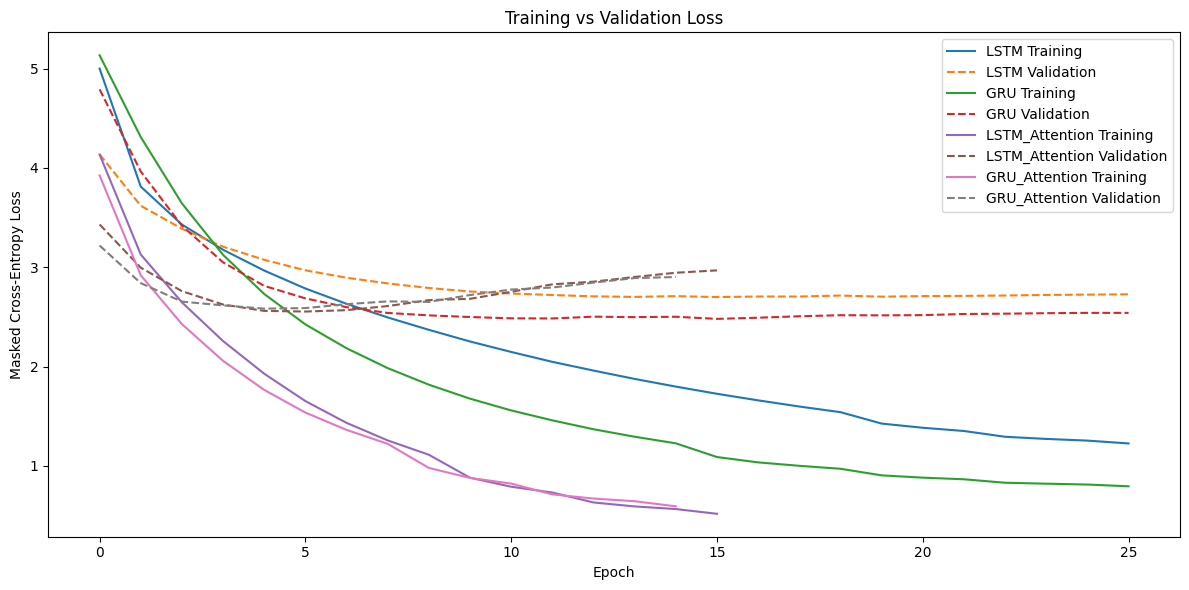

In [45]:

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["loss"],
        label=f"{name} Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Masked Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()


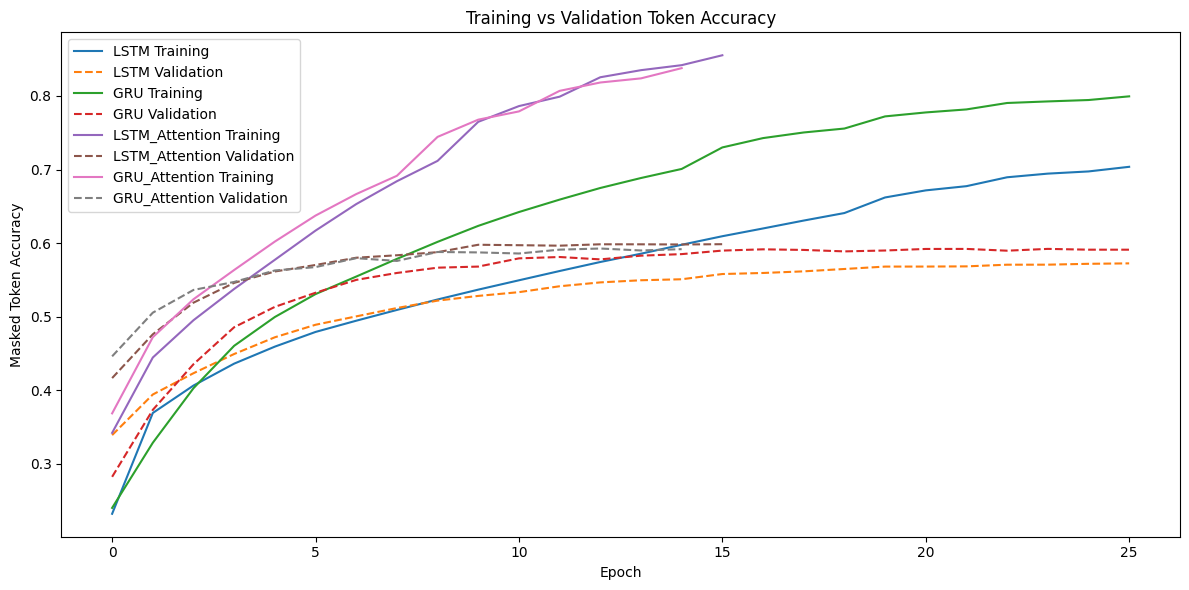

In [46]:

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["masked_accuracy"],
        label=f"{name} Training"
    )

    plt.plot(
        history.history["val_masked_accuracy"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("Training vs Validation Token Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Masked Token Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [47]:
evaluation_results = []

for name, model in models.items():

    print("\n" + "=" * 60)
    print(f"Evaluating: {name}")
    print("=" * 60)

    results = model.evaluate(
        test_dataset,
        verbose=1,
        return_dict=True
    )

    evaluation_results.append({
        "Model": name,
        "Test Loss": results["loss"],
        "Test Accuracy": results["masked_accuracy"]
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("\nFINAL TEST EVALUATION")
display(evaluation_df)


Evaluating: LSTM
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 2.6755 - masked_accuracy: 0.5529

Evaluating: GRU
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 2.4584 - masked_accuracy: 0.5905

Evaluating: LSTM_Attention
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 2.5038 - masked_accuracy: 0.5715

Evaluating: GRU_Attention
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 2.5574 - masked_accuracy: 0.5595

FINAL TEST EVALUATION


,Model,Test Loss,Test Accuracy
0,LSTM,2.675516,0.552899
1,GRU,2.458412,0.590457
2,LSTM_Attention,2.503795,0.571506
3,GRU_Attention,2.557446,0.559517


In [50]:

def translate_batch(sentences, model, batch_size=64):

    translations = []

    for start in range(0, len(sentences), batch_size):

        batch_sentences = sentences[
            start:start + batch_size
        ]

        batch_size_actual = len(batch_sentences)

        source = german_vectorizer(
            batch_sentences
        )

        source = tf.cast(source, tf.int32)

        decoder = np.zeros(
            (batch_size_actual, 39),
            dtype=np.int32
        )

        decoder[:, 0] = START_ID

        finished = np.zeros(
            batch_size_actual,
            dtype=bool
        )

        for t in range(38):

            decoder_tensor = tf.convert_to_tensor(
                decoder,
                dtype=tf.int32
            )

            predictions = model(
                [source, decoder_tensor],
                training=False
            )

            next_ids = tf.argmax(
                predictions[:, t, :],
                axis=-1,
                output_type=tf.int32
            ).numpy()

            active = ~finished

            next_ids[~active] = 0

            decoder[active, t + 1] = next_ids[active]

            finished |= (
                (next_ids == END_ID) |
                (next_ids == 0)
            )

            if finished.all():
                break

        for i in range(batch_size_actual):

            generated_ids = []

            for token_id in decoder[i, 1:]:

                if token_id == 0 or token_id == END_ID:
                    break

                generated_ids.append(int(token_id))

            words = [
                english_vocab[token_id]
                for token_id in generated_ids
            ]

            translations.append(" ".join(words))

    return translations


In [51]:
sample_sentences = [
    "Ein Mann spielt Gitarre.",
    "Ein Hund läuft im Park.",
    "Ein Kind spielt mit einem Ball.",
    "Eine Frau sitzt auf einer Bank."
]

predictions = translate_batch(
    sample_sentences,
    lstm_attention
)

for german, english in zip(sample_sentences, predictions):

    print("\nGerman:", german)
    print("Predicted English:", english)


German: Ein Mann spielt Gitarre.
Predicted English: sanitation workers playing golf .

German: Ein Hund läuft im Park.
Predicted English: sanitation workers walking in the rain .

German: Ein Kind spielt mit einem Ball.
Predicted English: sanitation barker members is playing with a rainstorm .

German: Eine Frau sitzt auf einer Bank.
Predicted English: sanitation workers sitting on a concrete platform .


In [52]:
!pip install -q sacrebleu

In [53]:
import sacrebleu

def remove_special_tokens(sentence):

    sentence = sentence.replace(
        "startseq ", "", 1
    )

    sentence = sentence.rsplit(
        " endseq", 1
    )[0]

    return sentence.strip()


references = [
    remove_special_tokens(sentence)
    for sentence in test_df["English"].tolist()
]

german_test_sentences = test_df["German"].tolist()

print("Test sentences:", len(german_test_sentences))
print("Reference example:", references[0])

Test sentences: 1000
Reference example: a man in an orange hat starring at something .


In [55]:

translation_results = []

all_predictions = {}

def detokenize_sentence(sentence):
    sentence = sentence.replace(" .", ".")
    sentence = sentence.replace(" ,", ",")
    sentence = sentence.replace(" !", "!")
    sentence = sentence.replace(" ?", "?")
    sentence = sentence.replace(" :", ":")
    sentence = sentence.replace(" ;", ";")
    sentence = sentence.replace(" ' ", "'")

    return " ".join(sentence.split())


for name, model in models.items():

    print("\n" + "=" * 60)
    print("TRANSLATION EVALUATION:", name)
    print("=" * 60)

    predictions = translate_batch(
        german_test_sentences,
        model,
        batch_size=64
    )

    all_predictions[name] = predictions

    references_clean = [
        detokenize_sentence(ref) for ref in references
    ]

    predictions_clean = [
        detokenize_sentence(pred) for pred in predictions
    ]

    bleu_score = sacrebleu.corpus_bleu(
        predictions_clean,
        [references_clean]
    ).score

    chrf_score = sacrebleu.corpus_chrf(
        predictions_clean,
        [references_clean]
    ).score

    translation_results.append({
        "Model": name,
        "BLEU": bleu_score,
        "chrF": chrf_score
    })

    print("BLEU:", round(bleu_score, 2))
    print("chrF:", round(chrf_score, 2))



TRANSLATION EVALUATION: LSTM
BLEU: 17.97
chrF: 35.69

TRANSLATION EVALUATION: GRU
BLEU: 22.04
chrF: 41.25

TRANSLATION EVALUATION: LSTM_Attention
BLEU: 20.45
chrF: 38.67

TRANSLATION EVALUATION: GRU_Attention
BLEU: 18.55
chrF: 37.29


In [56]:
translation_df = pd.DataFrame(
    translation_results
)

final_results = evaluation_df.merge(
    translation_df,
    on="Model"
)

final_results = final_results.sort_values(
    by="BLEU",
    ascending=False
).reset_index(drop=True)

print("\nFINAL NMT MODEL BENCHMARK")

display(final_results)


FINAL NMT MODEL BENCHMARK


,Model,Test Loss,Test Accuracy,BLEU,chrF
0,GRU,2.458412,0.590457,22.040814,41.250977
1,LSTM_Attention,2.503795,0.571506,20.453721,38.673188
2,GRU_Attention,2.557446,0.559517,18.548855,37.290312
3,LSTM,2.675516,0.552899,17.971537,35.693719


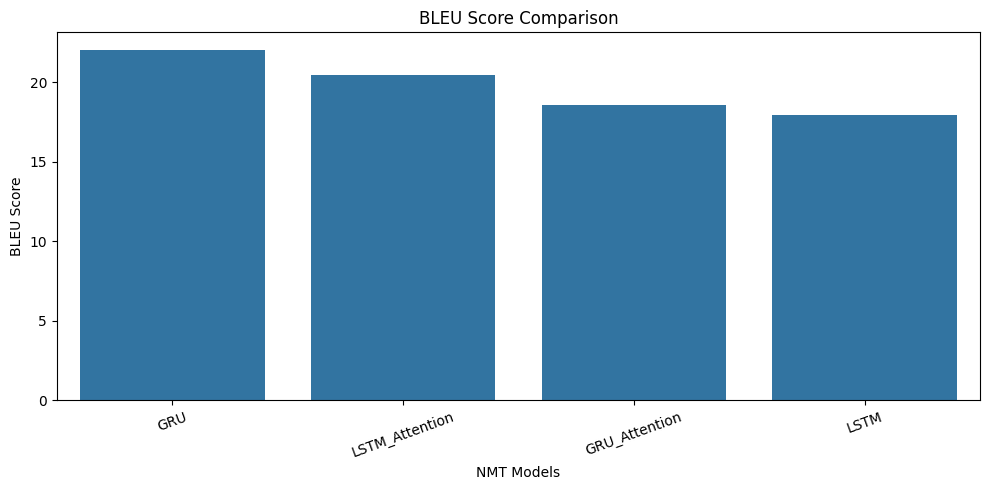

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x="Model",
    y="BLEU"
)

plt.title("BLEU Score Comparison")
plt.xlabel("NMT Models")
plt.ylabel("BLEU Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

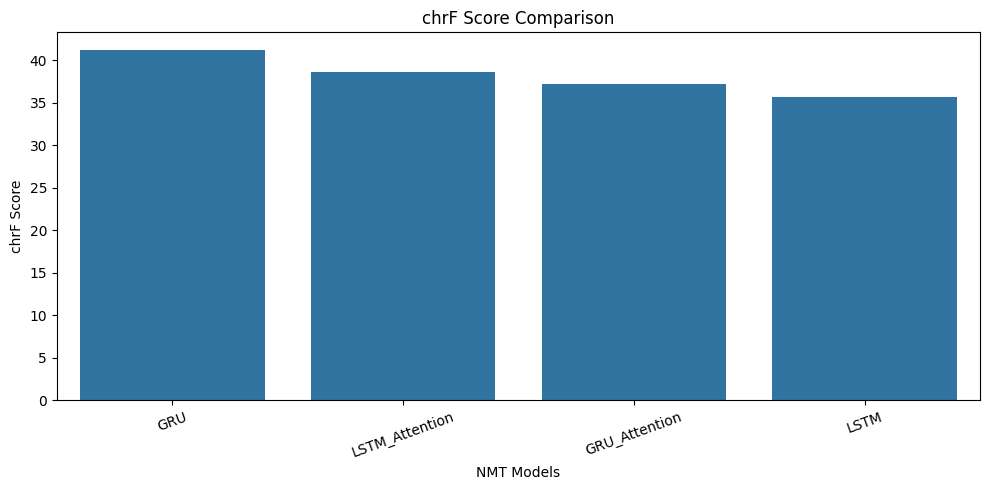

In [58]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x="Model",
    y="chrF"
)

plt.title("chrF Score Comparison")
plt.xlabel("NMT Models")
plt.ylabel("chrF Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

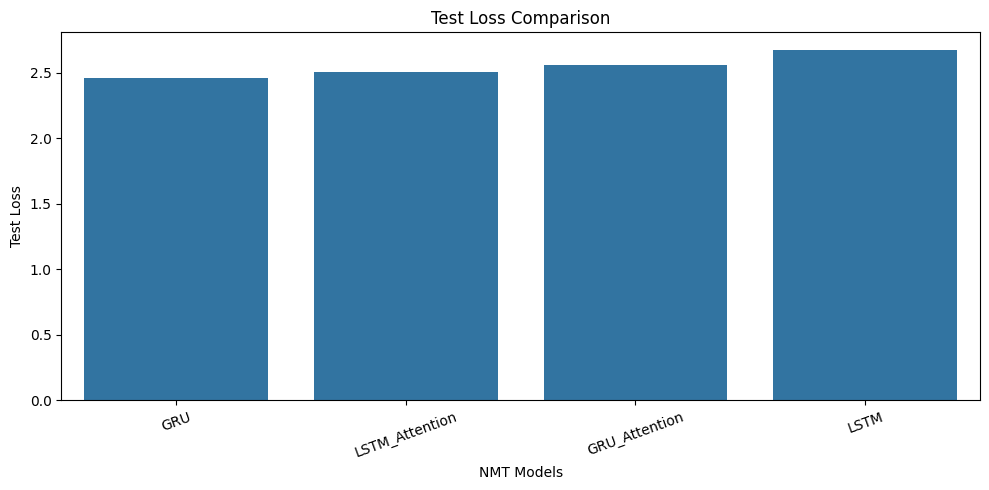

In [59]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x="Model",
    y="Test Loss"
)

plt.title("Test Loss Comparison")
plt.xlabel("NMT Models")
plt.ylabel("Test Loss")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [60]:
import os

RESULT_DIR = os.path.join(
    BASE_DIR,
    "evaluation_results"
)

os.makedirs(RESULT_DIR, exist_ok=True)

final_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

prediction_df = pd.DataFrame({
    "German": german_test_sentences,
    "Reference English": references,
    "LSTM Prediction": all_predictions["LSTM"],
    "GRU Prediction": all_predictions["GRU"],
    "LSTM Attention Prediction": all_predictions["LSTM_Attention"],
    "GRU Attention Prediction": all_predictions["GRU_Attention"]
})

prediction_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "test_predictions.csv"
    ),
    index=False
)

print("Evaluation results saved successfully!")

print("Location:", RESULT_DIR)

Evaluation results saved successfully!
Location: /content/drive/MyDrive/main/evaluation_results


~END~